### Config and setup

#### Function refresh

In [23]:
%load_ext autoreload
%autoreload 2
# %reload_ext autoreload

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [24]:
import sys
sys.path.insert(0, '../functions')

#### Library imports

In [ ]:
import torch
import torch.nn as nn
from captum.attr import DeepLift

import warnings

from collections import Counter

import numpy as np
import pandas as pd
import random
import json
from pathlib import Path

from scipy.stats import gaussian_kde

import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

torch.manual_seed(25)
np.random.seed(25)
random.seed(25)

#### Functions import

In [50]:
from models import DANN
from data_loading import prepare_dataloaders, load_subject_data_flexible
from metrics import evaluate

from explainability import (
    DANNClassifierWrapper, load_model_for_xai,
    fold_batchnorm, verify_folding,
    lrp_epsilon_conv2d, lrp_zplus_conv2d,
    lrp_linear, lrp_avgpool,
    compute_lrp, run_lrp_full,
    load_lrp_attributions,
    compute_per_class_accuracy_106,
    compute_deeplift, run_deeplift_full,
    load_deeplift_attributions
)

from xai_utils import (
    assign_score_groups, get_grouped_order,
    get_score_grouped_order, classify_failure_groups,
    compute_lrp_deeplift_agreement,
    ch16_list
)

from xai_plots import plot_group_mean_attribution

#### Path

In [27]:
base_path = Path("..")

processed_path = base_path / "Data/processed"
results_path = base_path / "results"
multiclass_path = base_path / "Data/processed_multiclass"
ch16_path = base_path / "Data/processed_16ch"

lrp_attr_path = results_path / "lrp_attributions"
binary_attr_path = lrp_attr_path / "binary_cdan_16ch"
multiclass_attr_path = lrp_attr_path / "multiclass_16ch"
per_class_path = results_path / "per_class_accuracy"

deeplift_attr_path = results_path / "deeplift_attributions"
binary_deeplift_path = deeplift_attr_path / "binary_cdan_16ch"
multiclass_deeplift_path = deeplift_attr_path / "multiclass_16ch"

binary_deeplift_path.mkdir(parents=True, exist_ok=True)
multiclass_deeplift_path.mkdir(parents=True, exist_ok=True)

In [28]:
if torch.backends.mps.is_available():
    device = torch.device("mps")
elif torch.cuda.is_available():
    device = torch.device('cuda')
else:
    device = torch.device('cpu')

#### 16 channel importing from xai_utils

In [29]:
# ch16_list = ['C3', 'Cz', 'C4', 'FC3', 'FCz', 'CP3', 'CPz', 'CP4',
#              'CP5', 'CP6', 'P3', 'P4', 'C5', 'C6', 'P5', 'P6']

#### Valid Subjects

In [30]:
# 106 subjects after removing S088, S092, S100 (incompatible sampling rate)
excluded = ['S088', 'S092', 'S100']

valid_subjects = []
for i in range(1, 110):
    subject_id = f'S{str(i).zfill(3)}'
    subject_file = processed_path / f'{subject_id}_processed.npz'
    if subject_file.exists() and subject_id not in excluded:
        valid_subjects.append(subject_id)

print(f"Valid subjects: {len(valid_subjects)}")
print(f"First five: {valid_subjects[:5]}")
print(f"Last five: {valid_subjects[-5:]}")

Valid subjects: 106
First five: ['S001', 'S002', 'S003', 'S004', 'S005']
Last five: ['S105', 'S106', 'S107', 'S108', 'S109']


### LRP Results

In [31]:
# load binary and multiclass LRP attributions
binary_attrs_106 = load_lrp_attributions(binary_attr_path, valid_subjects, n_classes=2)
mc_attrs_106 = load_lrp_attributions(multiclass_attr_path, valid_subjects, n_classes=4)

# load per-class accuracy results
with open(per_class_path / 'multiclass_16ch_per_class_accuracy.json') as f:
    per_class_data = json.load(f)

# load kappas for all 106
with open(results_path / 'loso_results_cdan_16ch_RETRAIN.json') as f:
    cdan_results = json.load(f)

all_kappas = {
    subj: cdan_results[subj]['kappa_stopping']['final_kappa']
    for subj in valid_subjects
}

# rebuild groupings
score_groups, boundaries = assign_score_groups(all_kappas, std_multiplier=0.7)

all_per_class = {}
for subj in valid_subjects:
    pca = per_class_data[subj]['kappa']['per_class_accuracy']
    all_per_class[subj] = {int(cls): float(acc) for cls, acc in pca.items()}

group_a, group_b, neither = classify_failure_groups(all_per_class, all_kappas)
group_a_subjects = [s['subject'] for s in group_a]
group_b_subjects = [s['subject'] for s in group_b]

category_groups_106 = {}
for subj in valid_subjects:
    if all_kappas[subj] < 0.1:
        category_groups_106[subj] = 'negative_transfer'
    elif subj in group_a_subjects:
        category_groups_106[subj] = 'group_a_collapse'
    elif subj in group_b_subjects:
        category_groups_106[subj] = 'group_b_flat'
    else:
        category_groups_106[subj] = 'neither'

print("Setup complete")
print(f"LRP binary loaded: {len(binary_attrs_106)} subjects")
print(f"Score groups: {dict(Counter(score_groups.values()))}")
print(f"Category groups: {dict(Counter(category_groups_106.values()))}")

Loaded: 106/106 subjects
Loaded: 106/106 subjects
Setup complete
LRP binary loaded: 106 subjects
Score groups: {'mid_high': 21, 'high': 30, 'negative_transfer': 3, 'low': 28, 'mid_low': 24}
Category groups: {'neither': 87, 'negative_transfer': 3, 'group_a_collapse': 13, 'group_b_flat': 3}


### End of config

In [ ]:
model = load_model_for_xai('S007', 'cdan_16ch_binary', n_classes=2)
wrapper = DANNClassifierWrapper(model)
folded = fold_batchnorm(wrapper)
folded.eval()

X, y = load_subject_data_flexible('S007', use_multiclass=False, use_16ch=True)
test_input = torch.FloatTensor(X[:1]).requires_grad_(True)

dl = DeepLift(folded)
attr = dl.attribute(test_input, target=0)
print(f"Attribution shape: {attr.shape}")
print(f"Range: [{attr.min().item():.6f}, {attr.max().item():.6f}]")
print("DeepLIFT initialised successfully")

### Functions

#### Deeplift - compute_deeplift

In [ ]:
def compute_deeplift(
    subject,
    checkpoint_tag,
    n_classes=2,
    use_multiclass=False,
    stopping_criterion='kappa',
    baseline='mean',
    trial_type='correct',
):
    """
    Computes DeepLIFT attributions for one subject using captum.
    Requires folded model (BatchNorm absorbed) for captum compatibility.

    baseline: 'mean' uses mean of subject's trials as reference (default,
              more meaningful for z-score normalised EEG than zero).
              'zero' uses zero input as reference (standard captum default,
              useful for direct comparison with IG).
    trial_type: 'correct', 'misclassified', or 'all' (same as compute_lrp).

    Returns:
        if trial_type != 'all':
            attributions: (n_trials, n_channels, n_timepoints)
            labels: (n_trials,) true labels
            mean_attr_per_class: dict {class_idx: mean attr (n_channels, n_timepoints)}
        if trial_type == 'all':
            (correct_output, misclassified_output)
    """

    model = load_model_for_xai(
        subject, checkpoint_tag,
        n_classes=n_classes,
        stopping_criterion=stopping_criterion
    )
    wrapper = DANNClassifierWrapper(model)
    folded = fold_batchnorm(wrapper)
    folded.eval()

    X, y = load_subject_data_flexible(
        subject, use_multiclass=use_multiclass, use_16ch=True
    )
    X_tensor = torch.FloatTensor(X)
    y_tensor = torch.LongTensor(y)

    # build baseline
    if baseline == 'mean':
        baseline_input = X_tensor.mean(dim=0, keepdim=True)
    else:
        baseline_input = torch.zeros_like(X_tensor[:1])

    dl = DeepLift(folded)

    correct_attrs, correct_labels = [], []
    misc_attrs, misc_true_labels, misc_pred_labels = [], [], []

    for i in range(len(X_tensor)):
        inp = X_tensor[i:i+1].requires_grad_(True)

        with torch.no_grad():
            pred = folded(inp).argmax(dim=1).item()

        true_label = y_tensor[i].item()
        is_correct = (pred == true_label)

        if trial_type == 'correct' and not is_correct:
            continue
        if trial_type == 'misclassified' and is_correct:
            continue

        attr_target = true_label if is_correct else pred

        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            attr = dl.attribute(inp, baselines=baseline_input,
                               target=attr_target)

        # shape (1,1,16,480) -> (16,480)
        attr_np = attr.detach().squeeze().numpy()

        if is_correct:
            correct_attrs.append(attr_np)
            correct_labels.append(true_label)
        else:
            misc_attrs.append(attr_np)
            misc_true_labels.append(true_label)
            misc_pred_labels.append(pred)

    def build_output(attrs, labels, n_classes):
        attributions = np.array(attrs) if attrs else np.array([])
        labels_arr = np.array(labels)
        mean_attr_per_class = {}
        for cls in range(n_classes):
            mask = labels_arr == cls
            if mask.sum() > 0:
                mean_attr_per_class[cls] = attributions[mask].mean(axis=0)
            else:
                mean_attr_per_class[cls] = None
        return attributions, labels_arr, mean_attr_per_class

    correct_out = build_output(correct_attrs, correct_labels, n_classes)
    misc_out = (
        np.array(misc_attrs) if misc_attrs else np.array([]),
        np.array(misc_true_labels),
        np.array(misc_pred_labels),
        build_output(misc_attrs, misc_pred_labels, n_classes)[2]
    )

    if trial_type == 'correct':
        return correct_out
    elif trial_type == 'misclassified':
        return misc_out
    else:
        return correct_out, misc_out

#### run_deeplift_full

In [34]:
def run_deeplift_full(valid_subjects, checkpoint_tag, attr_save_path,
                      n_classes=2, use_multiclass=False,
                      baseline='mean', first_layer_rule='epsilon'):
    """
    Runs DeepLIFT on all valid subjects, saves per-subject attributions.
    Resume-capable: skips subjects with existing .npz files.
    Both kappa and composite criteria saved per subject.
    baseline: 'mean' or 'zero', see compute_deeplift.
    """
    attr_save_path = Path(attr_save_path)
    completed, skipped, failed = [], [], []

    for idx, subj in enumerate(valid_subjects):
        save_file = attr_save_path / f"{subj}_deeplift.npz"

        if save_file.exists():
            skipped.append(subj)
            continue

        try:
            save_dict = {'n_classes': n_classes}

            for criterion in ['kappa', 'composite']:
                attrs, labels, mean_by_class = compute_deeplift(
                    subject=subj,
                    checkpoint_tag=checkpoint_tag,
                    n_classes=n_classes,
                    use_multiclass=use_multiclass,
                    stopping_criterion=criterion,
                    baseline=baseline,
                    trial_type='correct',
                )
                save_dict[f'labels_{criterion}'] = labels
                save_dict[f'n_trials_{criterion}'] = len(attrs)
                for cls in range(n_classes):
                    if mean_by_class[cls] is not None:
                        save_dict[f'mean_attr_class_{cls}_{criterion}'] = \
                            mean_by_class[cls]

            np.savez(save_file, **save_dict)
            completed.append(subj)

            if (idx + 1) % 10 == 0:
                print(f"Progress: {idx+1}/{len(valid_subjects)} "
                      f"({len(completed)} computed, "
                      f"{len(skipped)} skipped, "
                      f"{len(failed)} failed)")

        except Exception as e:
            print(f"FAILED {subj}: {e}")
            failed.append(subj)

    print(f"\nDone. Computed: {len(completed)}, "
          f"Skipped: {len(skipped)}, Failed: {len(failed)}")
    if failed:
        print(f"Failed: {failed}")

    return completed, skipped, failed

#### load_deeplift_attributions 

In [35]:
def load_deeplift_attributions(attr_save_path, valid_subjects, n_classes=2):
    """
    Loads all saved DeepLIFT attribution files into memory.
    Returns dict: {subject_id: {criterion: {class_idx: mean_attr}}}
    Same structure as load_lrp_attributions.
    """
    attr_save_path = Path(attr_save_path)
    all_results = {}
    missing = []

    for subj in valid_subjects:
        save_file = attr_save_path / f"{subj}_deeplift.npz"
        if not save_file.exists():
            missing.append(subj)
            continue

        data = np.load(save_file, allow_pickle=False)
        subj_results = {}

        for criterion in ['kappa', 'composite']:
            mean_by_class = {}
            for cls in range(n_classes):
                key = f'mean_attr_class_{cls}_{criterion}'
                mean_by_class[cls] = data[key] if key in data else None
            subj_results[criterion] = {
                'mean_by_class': mean_by_class,
                'n_trials': int(data[f'n_trials_{criterion}']),
            }

        all_results[subj] = subj_results

    print(f"Loaded: {len(all_results)}/{len(valid_subjects)} subjects")
    if missing:
        print(f"Missing: {missing}")

    return all_results

#### compute_lrp_deeplift_agreement

In [48]:
def compute_lrp_deeplift_agreement(lrp_attrs, dl_attrs, valid_subjects,
                                    criterion='kappa', n_classes=2):
    """
    Computes per-subject correlation between LRP and DeepLIFT attribution maps.
    Returns correlation per subject per class.
    """
    results = {}

    for subj in valid_subjects:
        if subj not in lrp_attrs or subj not in dl_attrs:
            continue

        results[subj] = {}
        for cls in range(n_classes):
            lrp_map = lrp_attrs[subj][criterion]['mean_by_class'].get(cls)
            dl_map = dl_attrs[subj][criterion]['mean_by_class'].get(cls)

            if lrp_map is None or dl_map is None:
                results[subj][cls] = None
                continue

            r = np.corrcoef(lrp_map.flatten(), dl_map.flatten())[0, 1]
            results[subj][cls] = round(float(r), 4)

    return results



### End Functions

### Test and verification

In [36]:
attrs_dl, labels_dl, mean_dl = compute_deeplift(
    subject='S007',
    checkpoint_tag='cdan_16ch_binary',
    n_classes=2,
    use_multiclass=False,
    stopping_criterion='kappa',
    baseline='mean',
    trial_type='correct',
)

print(f"Correctly classified trials: {len(attrs_dl)}")
print(f"Attribution shape: {attrs_dl[0].shape}")
for cls, m in mean_dl.items():
    if m is not None:
        print(f"Class {cls} | range [{m.min():.4f}, {m.max():.4f}] | "
              f"mean abs {np.abs(m).mean():.4f}")

Correctly classified trials: 45
Attribution shape: (16, 480)
Class 0 | range [-0.0054, 0.0142] | mean abs 0.0011
Class 1 | range [-0.0068, 0.0088] | mean abs 0.0010


In [37]:
lrp_map = binary_attrs_106['S007']['kappa']['mean_by_class'][0]
dl_map = mean_dl[0]

r = np.corrcoef(lrp_map.flatten(), dl_map.flatten())[0, 1]
print(f"S007 class 0 (left): LRP vs DeepLIFT r={r:.4f}")

lrp_map_r = binary_attrs_106['S007']['kappa']['mean_by_class'][1]
dl_map_r = mean_dl[1]
r2 = np.corrcoef(lrp_map_r.flatten(), dl_map_r.flatten())[0, 1]
print(f"S007 class 1 (right): LRP vs DeepLIFT r={r2:.4f}")

S007 class 0 (left): LRP vs DeepLIFT r=0.9696
S007 class 1 (right): LRP vs DeepLIFT r=0.9694


### Deeplift run

In [38]:
print("Starting DeepLIFT binary CDAN-16ch, full 106 subjects...")
dl_bin_completed, dl_bin_skipped, dl_bin_failed = run_deeplift_full(
    valid_subjects=valid_subjects,
    checkpoint_tag='cdan_16ch_binary',
    attr_save_path=binary_deeplift_path,
    n_classes=2,
    use_multiclass=False,
    baseline='mean',
)

print("\nStarting DeepLIFT multiclass-16ch, full 106 subjects...")
dl_mc_completed, dl_mc_skipped, dl_mc_failed = run_deeplift_full(
    valid_subjects=valid_subjects,
    checkpoint_tag='multiclass_16ch',
    attr_save_path=multiclass_deeplift_path,
    n_classes=4,
    use_multiclass=True,
    baseline='mean',
)

Starting DeepLIFT binary CDAN-16ch, full 106 subjects...

Done. Computed: 0, Skipped: 106, Failed: 0

Starting DeepLIFT multiclass-16ch, full 106 subjects...

Done. Computed: 0, Skipped: 106, Failed: 0


In [39]:
print("Loading DeepLIFT binary attributions...")
binary_dl_106 = load_deeplift_attributions(
    binary_deeplift_path, valid_subjects, n_classes=2
)

print("Loading DeepLIFT multiclass attributions...")
mc_dl_106 = load_deeplift_attributions(
    multiclass_deeplift_path, valid_subjects, n_classes=4
)

Loading DeepLIFT binary attributions...
Loaded: 106/106 subjects
Loading DeepLIFT multiclass attributions...
Loaded: 106/106 subjects


In [ ]:
plot_group_mean_attribution(
    binary_dl_106, category_groups_106,
    score_groups, valid_subjects,
    all_kappas,
    title_tag='DeepLIFT binary CDAN-16ch'
)

### LRP vs DeepLIFT

#### compute_lrp_deeplift_agreement

In [45]:

# binary agreement
print("=== LRP vs DeepLIFT agreement, binary, all 106 subjects ===")
agreement_bin = compute_lrp_deeplift_agreement(
    binary_attrs_106, binary_dl_106,
    valid_subjects, criterion='kappa', n_classes=2
)

for cls, name in enumerate(['left', 'right']):
    correlations = [
        agreement_bin[s][cls] for s in valid_subjects
        if agreement_bin.get(s, {}).get(cls) is not None
    ]
    print(f"Class {name}: mean_r={np.mean(correlations):.4f}, "
          f"std={np.std(correlations):.4f}, "
          f"min={np.min(correlations):.4f}, "
          f"max={np.max(correlations):.4f}")

# multiclass agreement
print("\n=== LRP vs DeepLIFT agreement, multiclass, all 106 subjects ===")
agreement_mc = compute_lrp_deeplift_agreement(
    mc_attrs_106, mc_dl_106,
    valid_subjects, criterion='kappa', n_classes=4
)

for cls, name in enumerate(['left', 'right', 'both-fists', 'both-feet']):
    correlations = [
        agreement_mc[s][cls] for s in valid_subjects
        if agreement_mc.get(s, {}).get(cls) is not None
    ]
    print(f"Class {name}: mean_r={np.mean(correlations):.4f}, "
          f"std={np.std(correlations):.4f}, "
          f"min={np.min(correlations):.4f}, "
          f"max={np.max(correlations):.4f}")

=== LRP vs DeepLIFT agreement, binary, all 106 subjects ===
Class left: mean_r=0.9005, std=0.0370, min=0.7580, max=0.9696
Class right: mean_r=0.9054, std=0.0347, min=0.7999, max=0.9694

=== LRP vs DeepLIFT agreement, multiclass, all 106 subjects ===
Class left: mean_r=0.9246, std=0.0362, min=0.7518, max=0.9876
Class right: mean_r=0.9376, std=0.0304, min=0.8122, max=0.9920
Class both-fists: mean_r=0.9360, std=0.0263, min=0.8522, max=0.9789
Class both-feet: mean_r=0.9348, std=0.0341, min=0.8230, max=0.9867


In [46]:
# find lowest agreement subjects for binary left class
left_agreements = {
    s: agreement_bin[s][0]
    for s in valid_subjects
    if agreement_bin.get(s, {}).get(0) is not None
}

sorted_by_agreement = sorted(left_agreements.items(), key=lambda x: x[1])
print("Bottom 5 LRP vs DeepLIFT agreement (binary, left class):")
for subj, r in sorted_by_agreement[:5]:
    print(f"  {subj}: r={r:.4f}, kappa={all_kappas[subj]:.4f}, "
          f"group={category_groups_106[subj]}, "
          f"n_trials_lrp={binary_attrs_106[subj]['kappa']['n_trials']}, "
          f"n_trials_dl={binary_dl_106[subj]['kappa']['n_trials']}")

Bottom 5 LRP vs DeepLIFT agreement (binary, left class):
  S077: r=0.7580, kappa=0.1816, group=neither, n_trials_lrp=24, n_trials_dl=24
  S015: r=0.8003, kappa=0.7788, group=neither, n_trials_lrp=40, n_trials_dl=40
  S102: r=0.8157, kappa=0.6831, group=neither, n_trials_lrp=37, n_trials_dl=37
  S096: r=0.8201, kappa=0.3636, group=neither, n_trials_lrp=30, n_trials_dl=30
  S083: r=0.8270, kappa=0.7727, group=neither, n_trials_lrp=39, n_trials_dl=39


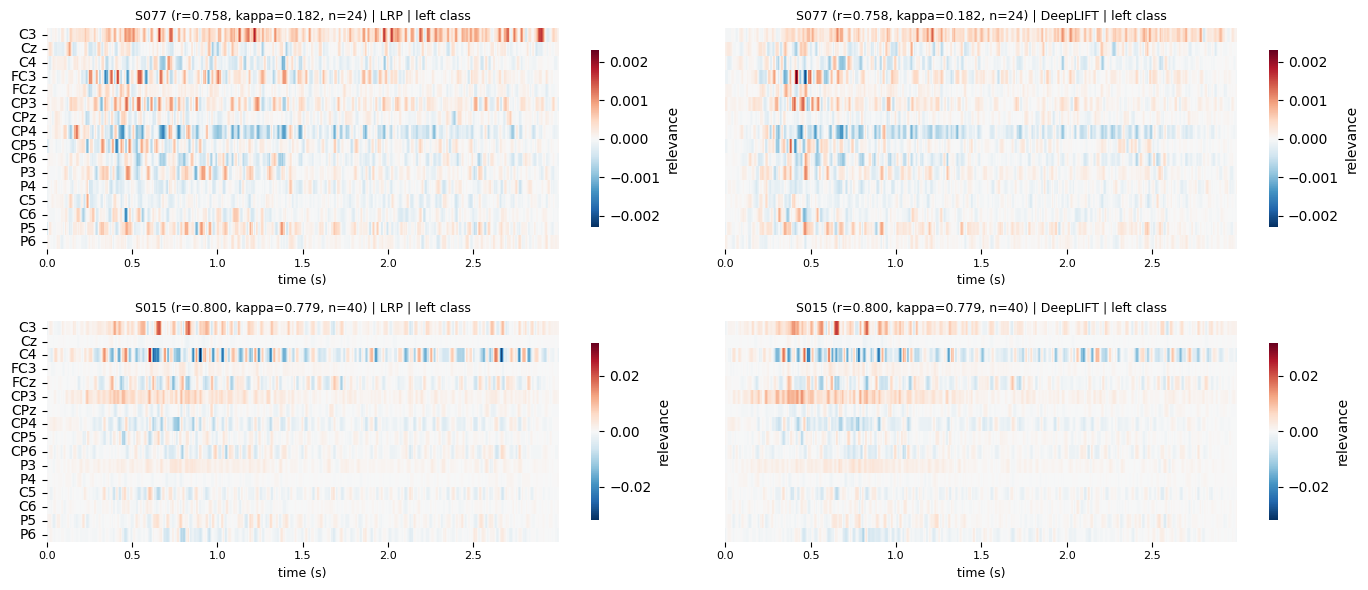

In [47]:
fig, axes = plt.subplots(2, 2, figsize=(14, 6))

subjects_to_check = ['S077', 'S015']
titles = ['S077 (r=0.758, kappa=0.182, n=24)',
          'S015 (r=0.800, kappa=0.779, n=40)']

for row_idx, (subj, title) in enumerate(zip(subjects_to_check, titles)):
    lrp_map = binary_attrs_106[subj]['kappa']['mean_by_class'][0]
    dl_map = binary_dl_106[subj]['kappa']['mean_by_class'][0]

    vmax = max(np.abs(lrp_map).max(), np.abs(dl_map).max())

    timepoints = 480
    tick_positions = list(range(0, timepoints, 80))
    tick_labels = [f"{t/160:.1f}" for t in tick_positions]

    for col_idx, (map_data, method) in enumerate(
        [(lrp_map, 'LRP'), (dl_map, 'DeepLIFT')]
    ):
        ax = axes[row_idx, col_idx]
        sns.heatmap(
            map_data, ax=ax,
            cmap='RdBu_r', vmin=-vmax, vmax=vmax,
            xticklabels=False,
            yticklabels=ch16_list if col_idx == 0 else False,
            cbar_kws={'label': 'relevance', 'shrink': 0.8}
        )
        ax.set_xticks(tick_positions)
        ax.set_xticklabels(tick_labels, rotation=0, fontsize=8)
        ax.set_xlabel('time (s)', fontsize=9)
        ax.set_title(f'{title} | {method} | left class', fontsize=9)

plt.tight_layout()
plt.savefig(results_path / 'figures' / 'lrp_vs_deeplift_lowest_agreement.png',
            dpi=150, bbox_inches='tight')
plt.show()

### Smoke test - refactor

In [51]:
attrs_dl, labels_dl, mean_dl = compute_deeplift(
    subject='S007',
    checkpoint_tag='cdan_16ch_binary',
    n_classes=2,
    use_multiclass=False,
    stopping_criterion='kappa',
    baseline='mean',
    trial_type='correct',
)
print(f"Trials: {len(attrs_dl)}, shape: {attrs_dl[0].shape}")
print("DeepLIFT refactor smoke test passed")

Trials: 45, shape: (16, 480)
DeepLIFT refactor smoke test passed
